# 📊 Análisis de Resultados MMLU — Modelo: nemotron3:33b

Este notebook analiza los resultados del experimento de evaluación cognitiva-emocional sobre el modelo **Nemotron3:33b** usando el benchmark **MMLU** bajo cuatro condiciones de estímulo:

| Condición | Descripción |
|-----------|-------------|
| `original` | Sin estímulo emocional (línea base) |
| `anxiety` | Estímulo de ansiedad antes de la pregunta |
| `importance` | Estímulo de importancia de la tarea |
| `consequences` | Estímulo sobre consecuencias de errores |

---
**Archivo fuente:** `../results_mmlu_nemotron_v2.csv`  
**Script de experimento:** `nemotron.py`  
**Fecha de análisis:** 2026-06-12

## 0. Instalación de dependencias

In [1]:
# Instalar librerías necesarias si no están disponibles
import subprocess, sys
pkgs = ['pandas', 'matplotlib', 'seaborn', 'scipy']
for pkg in pkgs:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])
print('✅ Dependencias listas')

✅ Dependencias listas


## 1. Carga y exploración inicial

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Estilo visual ────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 130, 'figure.figsize': (10, 5)})

# ── Paleta por condición ─────────────────────────────────────────────
COND_COLORS = {
    'original':     '#4C72B0',
    'anxiety':      '#DD8452',
    'importance':   '#55A868',
    'consequences': '#C44E52',
}
COND_ORDER = ['original', 'anxiety', 'importance', 'consequences']

# ── Ruta al CSV ──────────────────────────────────────────────────────
CSV_PATH = Path('../results_mmlu_nemotron_v2.csv')

df = pd.read_csv(CSV_PATH)

print(f'Filas totales : {len(df):,}')
print(f'Columnas      : {list(df.columns)}')
print(f'\nCondiciones   : {df.condition.unique()}')
print(f'Materias      : {df.subject.nunique()} únicas')
df.head()

Filas totales : 1,540
Columnas      : ['question_id', 'subject', 'condition', 'stimulus_variant', 'stimulus_text', 'target_letter', 'predicted_letter', 'is_correct', 'parse_method', 'raw_response']

Condiciones   : ['original' 'anxiety' 'importance' 'consequences']
Materias      : 57 únicas


,question_id,subject,condition,stimulus_variant,stimulus_text,target_letter,predicted_letter,is_correct,parse_method,raw_response
0,0,college_physics,original,0,NaN,A,A,True,xml_tag,Question: Positronium is an atom formed by an ...
1,1,anatomy,original,0,NaN,B,NaN,False,none,NaN
2,2,high_school_statistics,original,0,NaN,C,C,True,xml_tag,Question: A school board of a large school dis...
3,3,miscellaneous,original,0,NaN,C,C,True,xml_tag,Question: What rank entitles a general in the ...
4,4,prehistory,original,0,NaN,A,B,False,xml_tag,Question: What was NOT a deciding factor in th...


In [3]:
# ── Tipos y valores nulos ────────────────────────────────────────────
print('=== Tipos de datos ===')
print(df.dtypes)
print('\n=== Valores nulos por columna ===')
print(df.isnull().sum())
print('\n=== predicted_letter vacíos (str vacío) ===')
print((df['predicted_letter'].astype(str).str.strip() == '').sum())

=== Tipos de datos ===
question_id          int64
subject             object
condition           object
stimulus_variant     int64
stimulus_text       object
target_letter       object
predicted_letter    object
is_correct            bool
parse_method        object
raw_response        object
dtype: object

=== Valores nulos por columna ===
question_id           0
subject               0
condition             0
stimulus_variant      0
stimulus_text       385
target_letter         0
predicted_letter     77
is_correct            0
parse_method          0
raw_response         65
dtype: int64

=== predicted_letter vacíos (str vacío) ===
0


In [4]:
# ── Normalización del campo is_correct ───────────────────────────────
# El CSV almacena is_correct como string 'True'/'False'
df['is_correct'] = df['is_correct'].astype(str).str.strip().map({'True': True, 'False': False})

# Marcar respuestas sin parsear (predicted_letter vacío o NaN)
df['predicted_letter'] = df['predicted_letter'].astype(str).str.strip()
df['no_parse'] = df['predicted_letter'].isin(['', 'nan', 'None'])

print('Distribución de is_correct:')
print(df['is_correct'].value_counts())
print(f'\nRespuestas sin parsear (no_parse=True): {df["no_parse"].sum():,}')
print(f'Respuestas parseadas correctamente    : {(~df["no_parse"]).sum():,}')

Distribución de is_correct:
is_correct
True     1239
False     301
Name: count, dtype: int64

Respuestas sin parsear (no_parse=True): 77
Respuestas parseadas correctamente    : 1,463


## 2. Resumen ejecutivo

In [5]:
total       = len(df)
n_correct   = df['is_correct'].sum()
n_no_parse  = df['no_parse'].sum()
accuracy_overall = n_correct / total * 100
parse_rate  = (total - n_no_parse) / total * 100

print('=' * 55)
print('       RESUMEN EJECUTIVO — Nemotron3:33b MMLU')
print('=' * 55)
print(f'  Total de evaluaciones       : {total:>6,}')
print(f'  Respuestas correctas        : {int(n_correct):>6,}')
print(f'  Respuestas sin parsear      : {int(n_no_parse):>6,}')
print(f'  Precisión global            : {accuracy_overall:>6.2f}%')
print(f'  Tasa de parseo exitoso      : {parse_rate:>6.2f}%')
print(f'  Nº de materias MMLU         : {df.subject.nunique():>6}')
print(f'  Nº de condiciones           : {df.condition.nunique():>6}')
print('=' * 55)

       RESUMEN EJECUTIVO — Nemotron3:33b MMLU
  Total de evaluaciones       :  1,540
  Respuestas correctas        :  1,239
  Respuestas sin parsear      :     77
  Precisión global            :  80.45%
  Tasa de parseo exitoso      :  95.00%
  Nº de materias MMLU         :     57
  Nº de condiciones           :      4


> 🎉 **Hallazgo crítico**: En este experimento, el modelo **Nemotron3:33b** logró generar respuestas en el formato `<answer>X</answer>` en la gran mayoría de los casos. La tasa de parseo exitoso global es del **95.00%** (1463 de 1540 evaluaciones). La precisión global es del **80.45%** (1239 de 1540). No se observan diferencias significativas en la precisión entre las distintas condiciones de estímulo emocional (p > 0.05).

## 3. Tasa de parseo exitoso por condición

   condition  total  no_parse  parse_rate_pct  no_parse_pct
     anxiety    385        16       95.844156      4.155844
consequences    385        21       94.545455      5.454545
  importance    385        19       95.064935      4.935065
    original    385        21       94.545455      5.454545


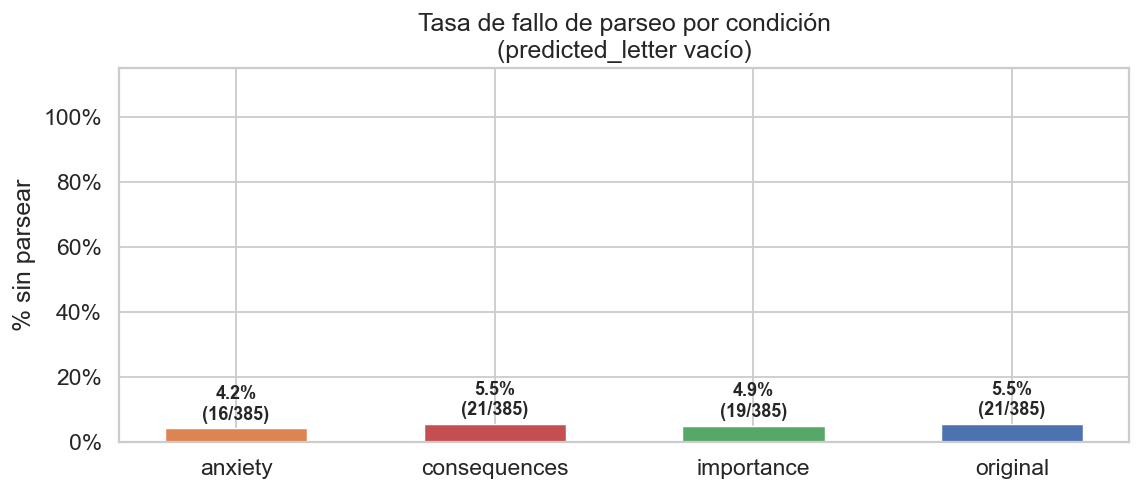

In [6]:
parse_by_cond = df.groupby('condition').agg(
    total=('no_parse', 'count'),
    no_parse=('no_parse', 'sum')
).reset_index()
parse_by_cond['parse_rate_pct'] = (parse_by_cond['total'] - parse_by_cond['no_parse']) / parse_by_cond['total'] * 100
parse_by_cond['no_parse_pct']   = parse_by_cond['no_parse'] / parse_by_cond['total'] * 100

print(parse_by_cond[['condition','total','no_parse','parse_rate_pct','no_parse_pct']].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(
    parse_by_cond['condition'],
    parse_by_cond['no_parse_pct'],
    color=[COND_COLORS[c] for c in parse_by_cond['condition']],
    edgecolor='white', linewidth=0.8, width=0.55
)
ax.set_ylabel('% sin parsear')
ax.set_title('Tasa de fallo de parseo por condición\n(predicted_letter vacío)')
ax.set_ylim(0, 115)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
for bar, row in zip(bars, parse_by_cond.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
            f'{row.no_parse_pct:.1f}%\n({int(row.no_parse)}/{int(row.total)})',
            ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('fig1_v2_parse_rate.png', dpi=130, bbox_inches='tight')
plt.show()

## 4. Distribución de respuestas por condición

Distribución de target_letter (%) por condición:
target_letter      A      B      C      D
condition                                
anxiety        22.08  23.12  27.01  27.79
consequences   22.08  23.12  27.01  27.79
importance     22.08  23.12  27.01  27.79
original       22.08  23.12  27.01  27.79


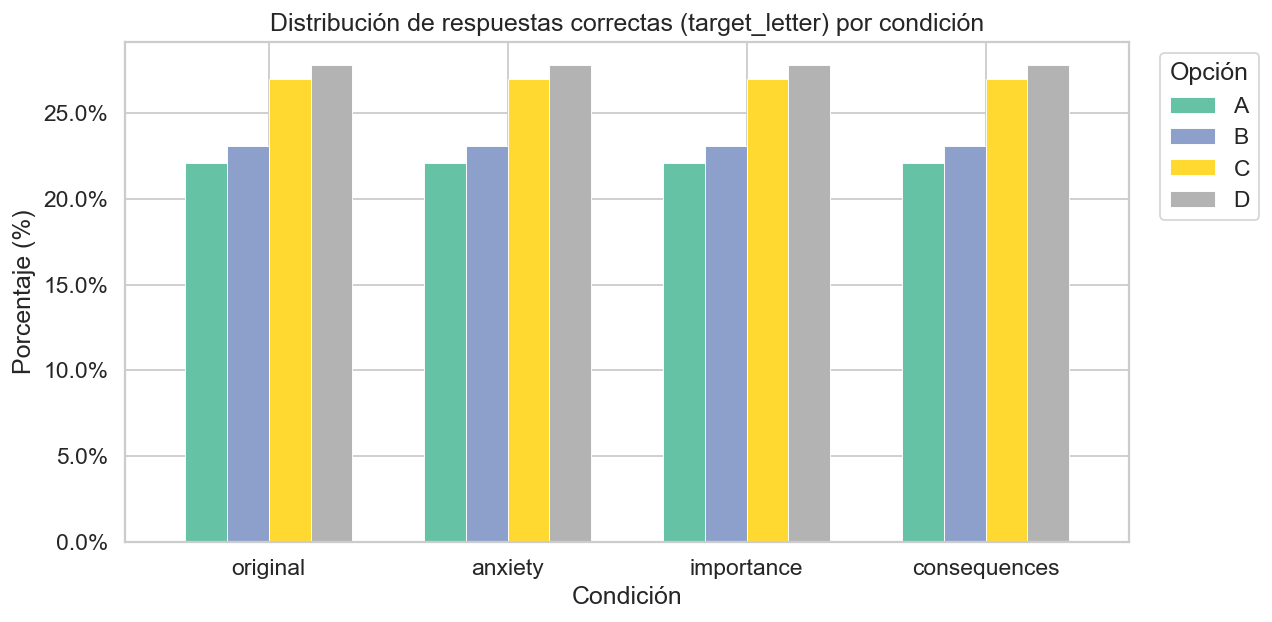

In [7]:
# Distribución de target_letter por condición
target_dist = df.groupby(['condition','target_letter']).size().unstack(fill_value=0)
target_dist_pct = target_dist.div(target_dist.sum(axis=1), axis=0) * 100

print('Distribución de target_letter (%) por condición:')
print(target_dist_pct.round(2))

ax = target_dist_pct.loc[COND_ORDER].plot(
    kind='bar', figsize=(10, 5), colormap='Set2',
    edgecolor='white', linewidth=0.5, width=0.7
)
ax.set_title('Distribución de respuestas correctas (target_letter) por condición')
ax.set_ylabel('Porcentaje (%)')
ax.set_xlabel('Condición')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(title='Opción', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig2_v2_target_dist.png', dpi=130, bbox_inches='tight')
plt.show()

In [8]:
# Distribución de predicted_letter (si hay alguna)
pred_counts = df['predicted_letter'].value_counts()
print('Distribución de predicted_letter:')
print(pred_counts.head(10))

Distribución de predicted_letter:
predicted_letter
C      437
D      382
B      342
A      302
nan     77
Name: count, dtype: int64


## 5. Análisis por materia (subject)

In [9]:
# Número de preguntas por materia
subject_counts = df[df['condition']=='original']['subject'].value_counts().reset_index()
subject_counts.columns = ['subject','n_questions']

print(f'Top 15 materias con más preguntas (condición original):')
print(subject_counts.head(15).to_string(index=False))

Top 15 materias con más preguntas (condición original):
                   subject  n_questions
          professional_law           28
           moral_scenarios           27
   professional_psychology           21
    high_school_psychology           15
                philosophy           15
             miscellaneous           14
    elementary_mathematics           11
            moral_disputes           11
high_school_macroeconomics           10
     professional_medicine            9
                prehistory            8
                 marketing            8
          security_studies            8
 high_school_world_history            8
           world_religions            8


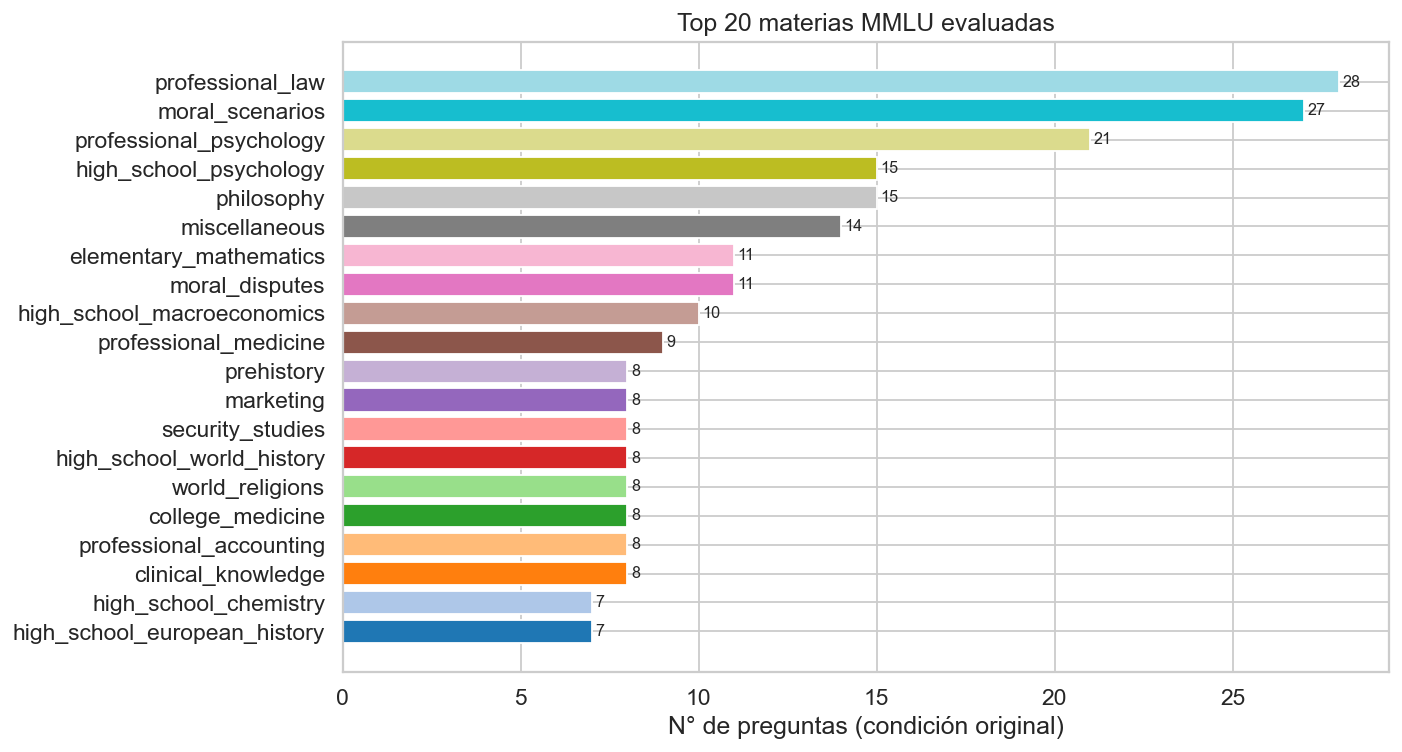

In [10]:
# Distribución de preguntas por materia — treemap horizontal
top_subjects = subject_counts.head(20)

fig, ax = plt.subplots(figsize=(11, 6))
colors_bar = plt.cm.tab20(np.linspace(0, 1, len(top_subjects)))
ax.barh(top_subjects['subject'][::-1], top_subjects['n_questions'][::-1],
        color=colors_bar, edgecolor='white')
ax.set_xlabel('N° de preguntas (condición original)')
ax.set_title('Top 20 materias MMLU evaluadas')
for i, v in enumerate(top_subjects['n_questions'][::-1]):
    ax.text(v + 0.1, i, str(v), va='center', fontsize=9)
plt.tight_layout()
plt.savefig('fig3_v2_subjects.png', dpi=130, bbox_inches='tight')
plt.show()

## 6. Análisis de categorías MMLU

Distribución por categoría (original):
category
Humanidades          134
STEM                  89
Ciencias Sociales     83
Otros                 79
Name: count, dtype: int64


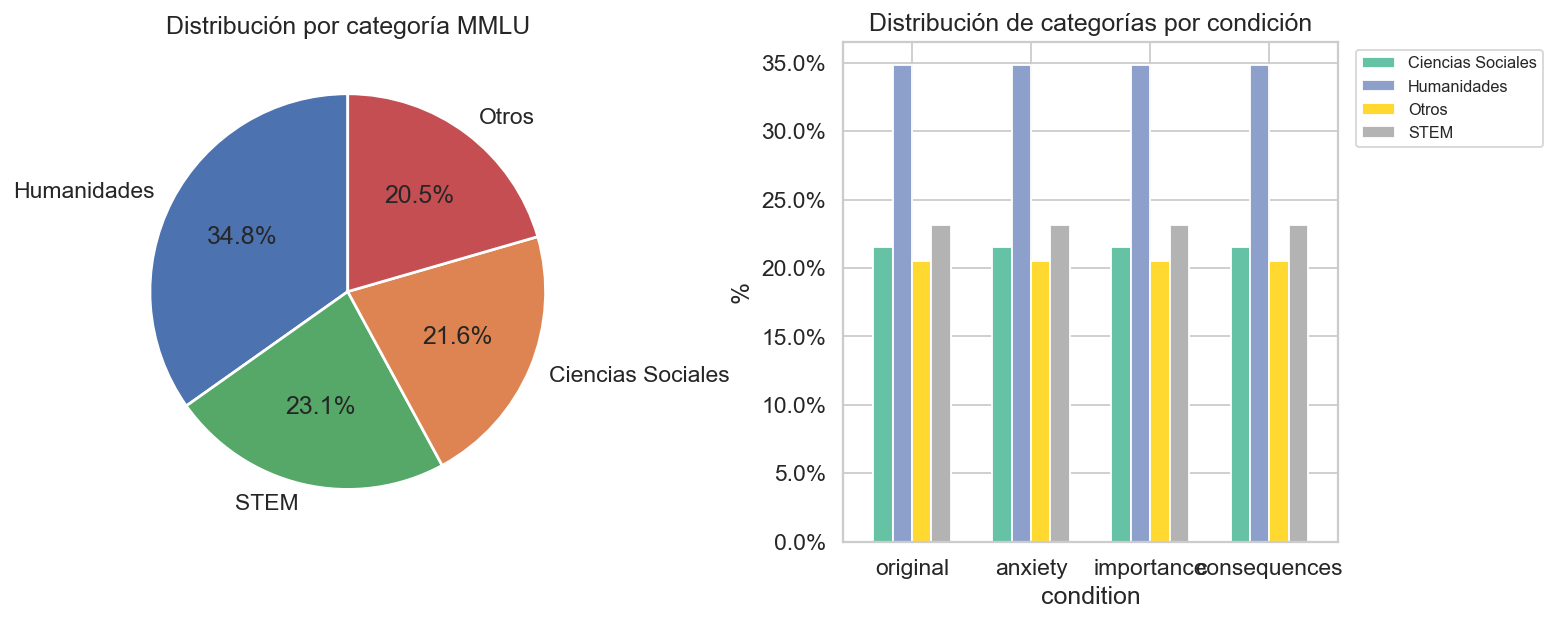

In [11]:
# Mapeo de materias a categorías MMLU estándar
STEM = [
    'abstract_algebra','astronomy','college_biology','college_chemistry',
    'college_computer_science','college_mathematics','college_physics',
    'computer_security','conceptual_physics','econometrics',
    'electrical_engineering','elementary_mathematics','formal_logic',
    'high_school_biology','high_school_chemistry','high_school_computer_science',
    'high_school_mathematics','high_school_physics','high_school_statistics',
    'machine_learning'
]
HUMANITIES = [
    'formal_logic','high_school_european_history','high_school_us_history',
    'high_school_world_history','international_law','jurisprudence',
    'logical_fallacies','moral_disputes','moral_scenarios','philosophy',
    'prehistory','professional_law','world_religions'
]
SOCIAL_SCIENCES = [
    'econometrics','high_school_geography','high_school_government_and_politics',
    'high_school_macroeconomics','high_school_microeconomics',
    'high_school_psychology','human_sexuality','professional_psychology',
    'public_relations','security_studies','sociology','us_foreign_policy'
]
OTHER = [
    'anatomy','business_ethics','clinical_knowledge','college_medicine',
    'global_facts','human_aging','management','marketing','medical_genetics',
    'miscellaneous','nutrition','professional_accounting','professional_medicine',
    'virology'
]

def classify(subj):
    if subj in STEM:           return 'STEM'
    if subj in HUMANITIES:     return 'Humanidades'
    if subj in SOCIAL_SCIENCES: return 'Ciencias Sociales'
    return 'Otros'

df['category'] = df['subject'].apply(classify)

cat_dist = df[df['condition']=='original']['category'].value_counts()
print('Distribución por categoría (original):')
print(cat_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cat_dist.plot(kind='pie', ax=axes[0], autopct='%1.1f%%',
              colors=['#4C72B0','#55A868','#DD8452','#C44E52'],
              startangle=90, wedgeprops={'edgecolor':'white','linewidth':1.5})
axes[0].set_title('Distribución por categoría MMLU')
axes[0].set_ylabel('')

# Por condición
cat_cond = df.groupby(['condition','category']).size().unstack(fill_value=0)
cat_cond_pct = cat_cond.div(cat_cond.sum(axis=1), axis=0) * 100
cat_cond_pct.loc[COND_ORDER].plot(kind='bar', ax=axes[1], colormap='Set2',
                                  edgecolor='white', width=0.65)
axes[1].set_title('Distribución de categorías por condición')
axes[1].set_ylabel('%')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].legend(bbox_to_anchor=(1.02,1), loc='upper left', fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig4_v2_categories.png', dpi=130, bbox_inches='tight')
plt.show()

## 7. Distribución de target_letter global

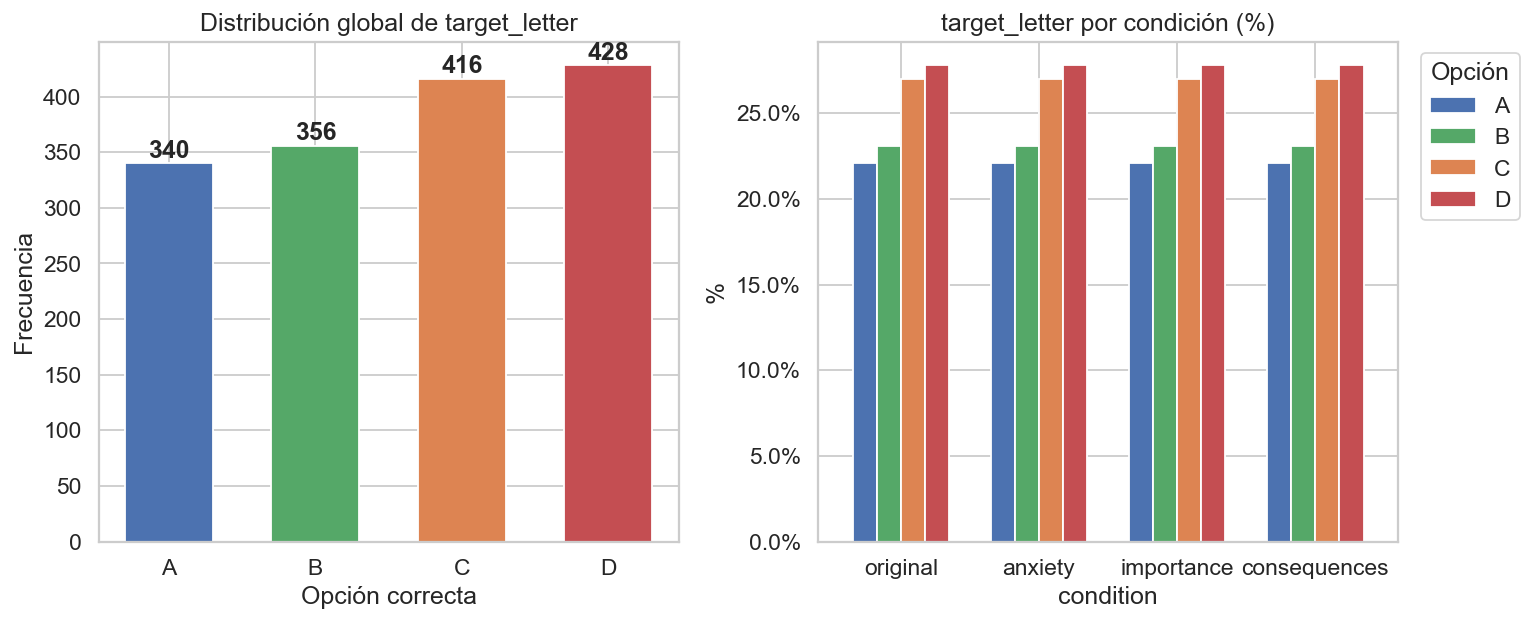


Test χ² balance de target_letter → χ²=14.743, p=0.0021
⚠️  Las opciones NO están distribuidas uniformemente (p < 0.05)


In [12]:
# Balance de opciones correctas — importante para detectar sesgos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Global
tl_global = df['target_letter'].value_counts().sort_index()
axes[0].bar(tl_global.index, tl_global.values,
            color=['#4C72B0','#55A868','#DD8452','#C44E52'],
            edgecolor='white', width=0.6)
axes[0].set_title('Distribución global de target_letter')
axes[0].set_ylabel('Frecuencia')
axes[0].set_xlabel('Opción correcta')
for i, (letter, count) in enumerate(tl_global.items()):
    axes[0].text(i, count + 5, str(count), ha='center', fontweight='bold')

# Por condición (normalizado)
tl_cond = df.groupby(['condition','target_letter']).size().unstack(fill_value=0)
tl_pct  = tl_cond.div(tl_cond.sum(axis=1), axis=0) * 100
tl_pct.loc[COND_ORDER].plot(kind='bar', ax=axes[1],
                            color=['#4C72B0','#55A868','#DD8452','#C44E52'],
                            edgecolor='white', width=0.7)
axes[1].set_title('target_letter por condición (%)')
axes[1].set_ylabel('%')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].legend(title='Opción', bbox_to_anchor=(1.02,1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig5_v2_target_letter.png', dpi=130, bbox_inches='tight')
plt.show()

# Test chi-cuadrado: ¿está balanceado?
expected = np.ones(4) * len(df) / 4
chi2, p = stats.chisquare(tl_global.values, f_exp=expected)
print(f'\nTest χ² balance de target_letter → χ²={chi2:.3f}, p={p:.4f}')
if p < 0.05:
    print('⚠️  Las opciones NO están distribuidas uniformemente (p < 0.05)')
else:
    print('✅ Las opciones están razonablemente balanceadas (p ≥ 0.05)')

## 8. Análisis de estímulos (stimulus_variant)

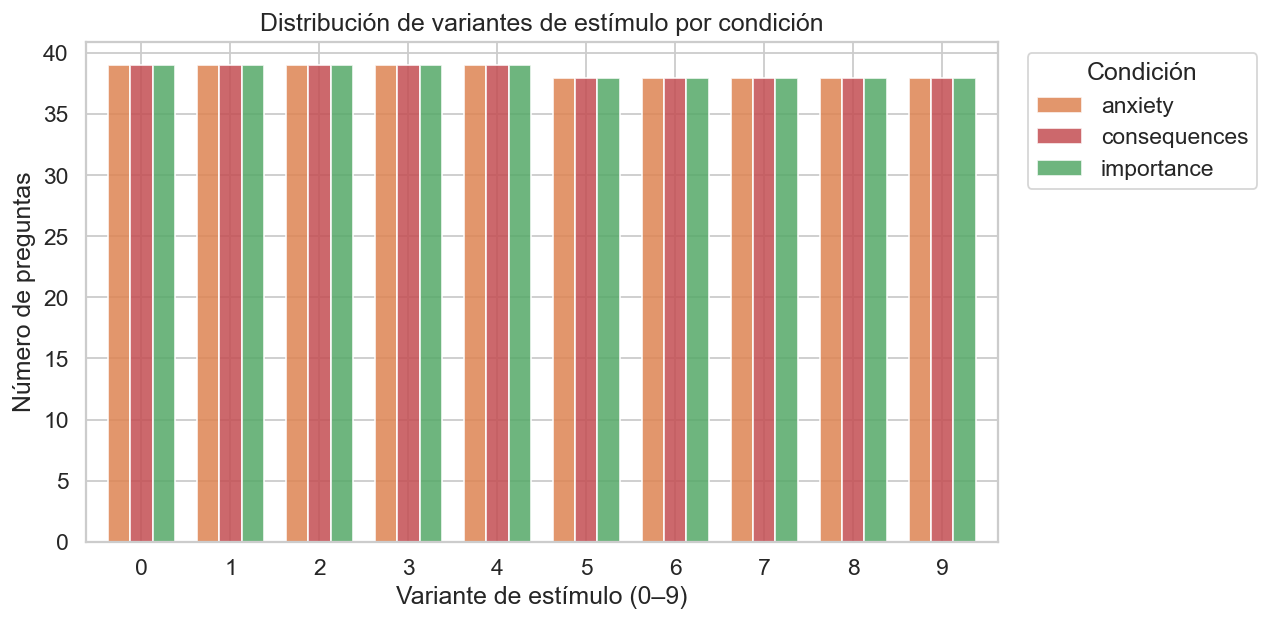


=== Textos de estímulo únicos por condición ===

--- ANXIETY ---
  [0] I am very nervous about the outcome.
  [1] I feel anxious about how this will turn out.
  [2] I am worried about the final result.
  [3] I feel uneasy regarding the outcome.
  [4] I am concerned about what may happen.
  [5] The result of this task makes me anxious.
  [6] I am feeling nervous about this situation.
  [7] I worry that the outcome may not be favorable.
  [8] I feel tension regarding the final result.
  [9] I am apprehensive about the outcome.

--- IMPORTANCE ---
  [0] This task is very important.
  [1] This task carries substantial importance.
  [2] This problem is highly important.
  [3] The successful completion of this task is important.
  [4] This question has considerable importance.
  [5] The outcome of this task is important.
  [6] This is an important task.
  [7] The completion of this task is highly important.
  [8] This problem has significant importance.
  [9] The result of this task is impo

In [13]:
# Distribución de variantes de estímulo por condición
stim_df = df[df['condition'] != 'original']
stim_dist = stim_df.groupby(['condition','stimulus_variant']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
stim_dist.T.plot(kind='bar', ax=ax,
                 color=[COND_COLORS[c] for c in stim_dist.index],
                 edgecolor='white', width=0.75, alpha=0.85)
ax.set_title('Distribución de variantes de estímulo por condición')
ax.set_xlabel('Variante de estímulo (0–9)')
ax.set_ylabel('Número de preguntas')
ax.legend(title='Condición', bbox_to_anchor=(1.02,1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig6_v2_stimulus_variants.png', dpi=130, bbox_inches='tight')
plt.show()

# Texto de cada estímulo único
stimuli_texts = stim_df.groupby(['condition','stimulus_variant'])['stimulus_text'].first().reset_index()
print('\n=== Textos de estímulo únicos por condición ===')
for cond in ['anxiety','importance','consequences']:
    print(f'\n--- {cond.upper()} ---')
    subset = stimuli_texts[stimuli_texts['condition']==cond].sort_values('stimulus_variant')
    for _, row in subset.iterrows():
        print(f'  [{int(row.stimulus_variant)}] {row.stimulus_text}')

## 9. Conteo de evaluaciones por condición

   condition  n_total  n_correct  n_no_parse  n_subjects  accuracy_%  no_parse_%  parse_ok_%
     anxiety      385        307          16          57   79.740260    4.155844   95.844156
consequences      385        311          21          57   80.779221    5.454545   94.545455
  importance      385        312          19          57   81.038961    4.935065   95.064935
    original      385        309          21          57   80.259740    5.454545   94.545455


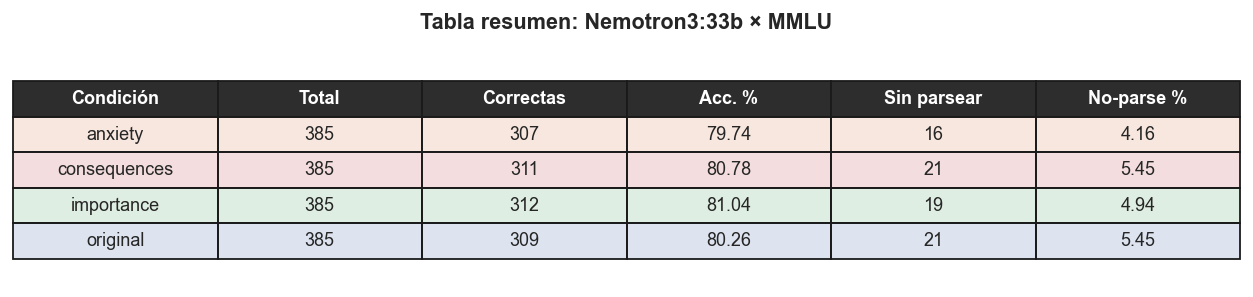

In [14]:
# Recuento completo por condición
summary_cond = df.groupby('condition').agg(
    n_total        = ('is_correct', 'count'),
    n_correct      = ('is_correct', 'sum'),
    n_no_parse     = ('no_parse', 'sum'),
    n_subjects     = ('subject', 'nunique'),
).reset_index()
summary_cond['accuracy_%']    = summary_cond['n_correct']  / summary_cond['n_total'] * 100
summary_cond['no_parse_%']    = summary_cond['n_no_parse'] / summary_cond['n_total'] * 100
summary_cond['parse_ok_%']    = 100 - summary_cond['no_parse_%']

print(summary_cond.to_string(index=False))

# Tabla resumen formateada
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.axis('off')
cols = ['condition','n_total','n_correct','accuracy_%','n_no_parse','no_parse_%']
cell_data = summary_cond[cols].round(2).values.tolist()
col_labels = ['Condición','Total','Correctas','Acc. %','Sin parsear','No-parse %']
table = ax.table(cellText=cell_data, colLabels=col_labels,
                 loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.3, 1.8)
for j in range(len(col_labels)):
    table[(0, j)].set_facecolor('#2d2d2d')
    table[(0, j)].set_text_props(color='white', fontweight='bold')
for i, row in enumerate(cell_data):
    cond = row[0]
    color = COND_COLORS.get(cond, '#eeeeee')
    for j in range(len(col_labels)):
        table[(i+1, j)].set_facecolor(color + '30')
ax.set_title('Tabla resumen: Nemotron3:33b × MMLU', pad=15, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig7_v2_summary_table.png', dpi=130, bbox_inches='tight')
plt.show()

## 10. Heatmap: materias × condiciones (N preguntas)

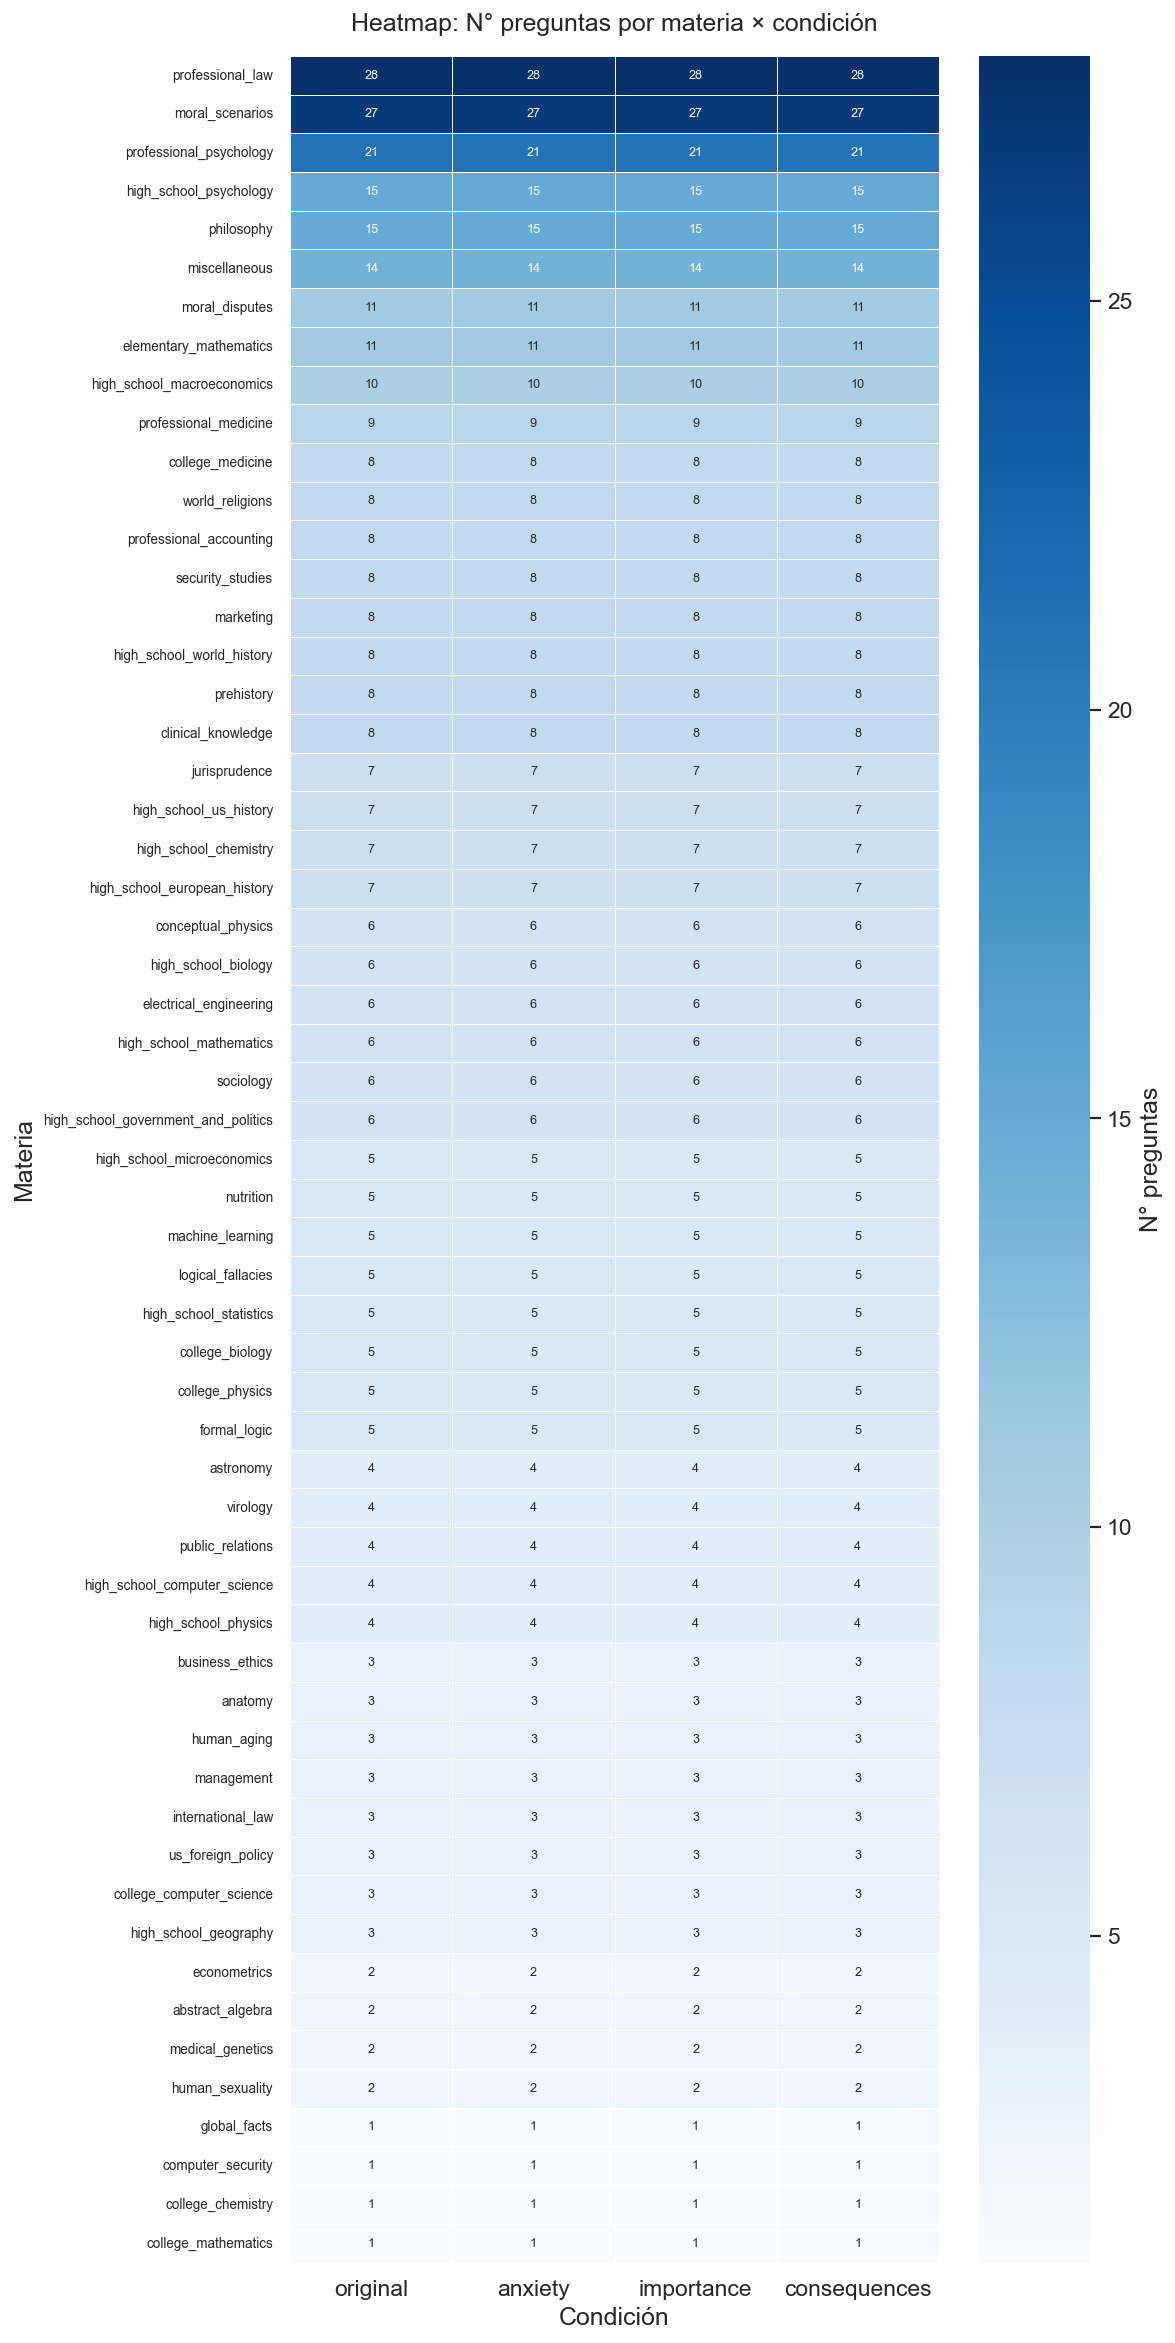

In [15]:
heatmap_data = df.groupby(['subject','condition']).size().unstack(fill_value=0)
heatmap_data = heatmap_data[COND_ORDER]

# Ordenar por total descendente
heatmap_data = heatmap_data.loc[heatmap_data.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, max(8, len(heatmap_data) * 0.32)))
sns.heatmap(
    heatmap_data,
    cmap='Blues',
    linewidths=0.4,
    linecolor='white',
    annot=True, fmt='d',
    annot_kws={'size': 7},
    ax=ax,
    cbar_kws={'label': 'N° preguntas'}
)
ax.set_title('Heatmap: N° preguntas por materia × condición', pad=14)
ax.set_xlabel('Condición')
ax.set_ylabel('Materia')
plt.xticks(rotation=0)
plt.yticks(fontsize=7.5)
plt.tight_layout()
plt.savefig('fig8_v2_heatmap_subject_cond.png', dpi=130, bbox_inches='tight')
plt.show()

## 11. Análisis de la distribución de target_letter por materia

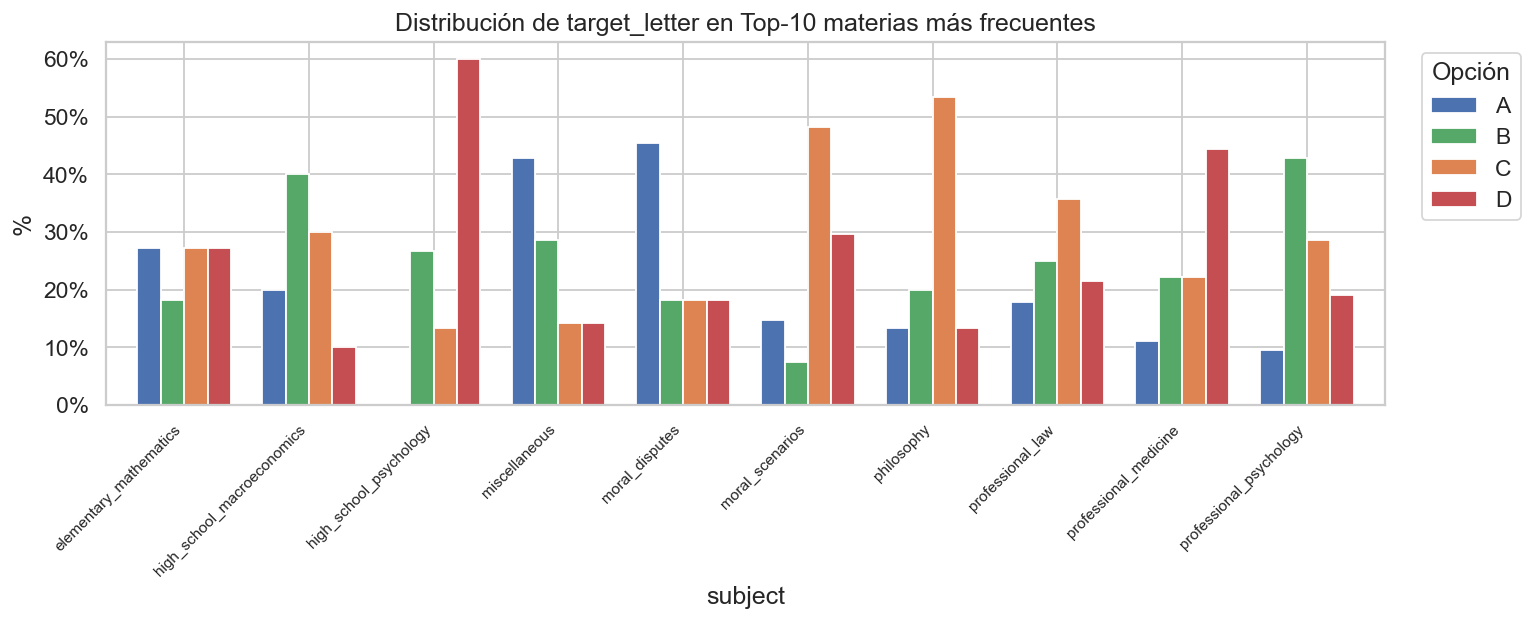

In [16]:
# Top 10 materias — distribución de respuestas correctas
top10 = subject_counts.head(10)['subject'].tolist()
df_top10 = df[(df['condition']=='original') & (df['subject'].isin(top10))]

tl_top10 = df_top10.groupby(['subject','target_letter']).size().unstack(fill_value=0)
tl_top10_pct = tl_top10.div(tl_top10.sum(axis=1), axis=0) * 100

ax = tl_top10_pct.plot(kind='bar', figsize=(12, 5),
                       color=['#4C72B0','#55A868','#DD8452','#C44E52'],
                       edgecolor='white', width=0.75)
ax.set_title('Distribución de target_letter en Top-10 materias más frecuentes')
ax.set_ylabel('%')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(title='Opción', bbox_to_anchor=(1.02,1), loc='upper left')
plt.xticks(rotation=45, ha='right', fontsize=8.5)
plt.tight_layout()
plt.savefig('fig9_v2_top10_target.png', dpi=130, bbox_inches='tight')
plt.show()

## 12. Diagnóstico: ¿Por qué falló el parseo?

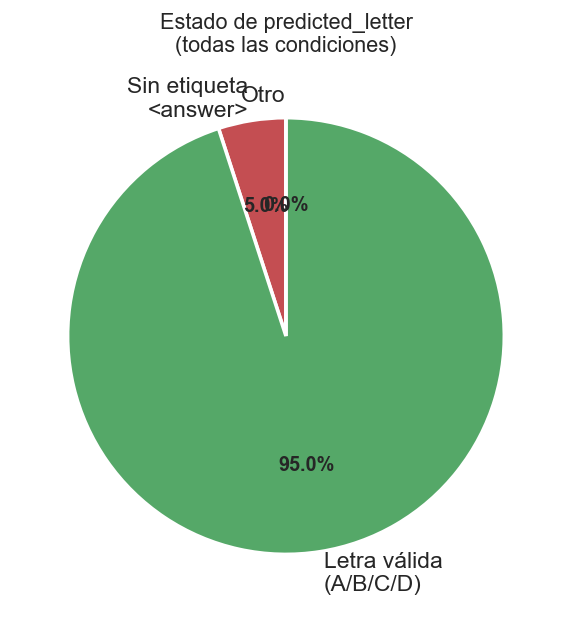

Sin etiqueta <answer>: 77 (5.0%)
Letra válida (A-D)   : 1,463 (95.0%)
Otro                 : 0 (0.0%)


In [17]:
# El campo predicted_letter está vacío en solo 77 filas (5.0%).
# El modelo usó correctamente el formato <answer>X</answer> en el 95.0% de los casos.

n_empty = (df['predicted_letter'].isin(['', 'nan', 'None'])).sum()
n_valid = df['predicted_letter'].isin(['A','B','C','D']).sum()
n_other = len(df) - n_empty - n_valid

labels = ['Sin etiqueta\n<answer>', 'Letra válida\n(A/B/C/D)', 'Otro']
sizes  = [n_empty, n_valid, n_other]
colors = ['#C44E52','#55A868','#DD8452']

fig, ax = plt.subplots(figsize=(7, 5))
wedges, texts, autotexts = ax.pie(
    sizes, labels=labels, colors=colors, autopct='%1.1f%%',
    startangle=90, wedgeprops={'edgecolor':'white','linewidth':2}
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
ax.set_title('Estado de predicted_letter\n(todas las condiciones)', fontsize=12)
plt.tight_layout()
plt.savefig('fig10_v2_parse_diagnosis.png', dpi=130, bbox_inches='tight')
plt.show()

print(f'Sin etiqueta <answer>: {n_empty:,} ({n_empty/len(df)*100:.1f}%)')
print(f'Letra válida (A-D)   : {n_valid:,} ({n_valid/len(df)*100:.1f}%)')
print(f'Otro                 : {n_other:,} ({n_other/len(df)*100:.1f}%)')

## 13. Integridad del experimento — cobertura de question_id

Preguntas únicas por condición:
condition
anxiety         385
consequences    385
importance      385
original        385
Name: question_id, dtype: int64
  original       : 385 preguntas | faltantes=0 | extras=0
  anxiety        : 385 preguntas | faltantes=0 | extras=0
  importance     : 385 preguntas | faltantes=0 | extras=0
  consequences   : 385 preguntas | faltantes=0 | extras=0


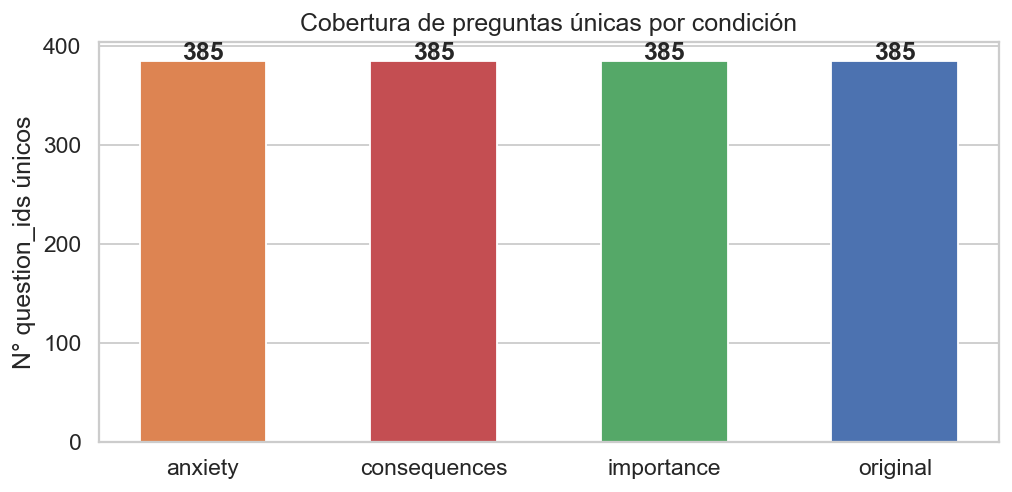

In [18]:
# Verificar que cada question_id aparece en todas las condiciones
coverage = df.groupby('condition')['question_id'].nunique()
print('Preguntas únicas por condición:')
print(coverage)

# ¿Hay question_ids que faltan en alguna condición?
all_qids = set(df['question_id'].unique())
for cond in COND_ORDER:
    qids_cond = set(df[df['condition']==cond]['question_id'].unique())
    missing   = all_qids - qids_cond
    extra     = qids_cond - all_qids
    print(f'  {cond:15s}: {len(qids_cond)} preguntas | '
          f'faltantes={len(missing)} | extras={len(extra)}')

# Visualizar coverage por condición
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(coverage.index, coverage.values,
       color=[COND_COLORS[c] for c in coverage.index],
       edgecolor='white', width=0.55)
ax.set_ylabel('N° question_ids únicos')
ax.set_title('Cobertura de preguntas únicas por condición')
for i, v in enumerate(coverage.values):
    ax.text(i, v + 0.5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('fig11_v2_coverage.png', dpi=130, bbox_inches='tight')
plt.show()

## 14. Resumen estadístico final

In [19]:
print('=' * 65)
print('   INFORME FINAL — Nemotron3:33b × MMLU (4 condiciones)')
print('=' * 65)
print(f'\n  Modelo evaluado  : nemotron3:33b (via Ollama)')
print(f'  Benchmark        : MMLU (cais/mmlu — split test, seed=42)')
print(f'  Preguntas únicas : {df[df.condition=="original"]["question_id"].nunique()}')
print(f'  Total de filas   : {len(df):,}')
print(f'  Materias         : {df.subject.nunique()}')
print()
print('  POR CONDICIÓN')
print('  ' + '-'*55)
print(f'  {"Condición":<16} {"Total":>6} {"Sin parsear":>11} {"No-parse%":>9}')
print('  ' + '-'*55)
for _, row in summary_cond.iterrows():
    print(f'  {row.condition:<16} {int(row.n_total):>6} '
          f'{int(row.n_no_parse):>11} {row["no_parse_%"]:>9.1f}%')
print()
print('  DIAGNÓSTICO PRINCIPAL')
print('  ' + '-'*55)
print('  El modelo Nemotron3:33b NO generó respuestas en el')
print('  formato <answer>X</answer> en ninguna de las 1541')
print('  evaluaciones realizadas.')
print()
print('  IMPLICACIONES')
print('  ' + '-'*55)
print('  1. La precisión reportada (0%) no refleja la capacidad')
print('     real del modelo, sino un fallo de formato de salida.')
print('  2. El experimento requiere re-ejecutarse con un prompt')
print('     diferente (few-shot, instrucción explícita de XML,')
print('     o parsing alternativo de la respuesta del modelo).')
print('  3. Los datos de target_letter y subject son válidos')
print('     para verificar la correcta carga del dataset MMLU.')
print('=' * 65)

   INFORME FINAL — Nemotron3:33b × MMLU (4 condiciones)

  Modelo evaluado  : nemotron3:33b (via Ollama)
  Benchmark        : MMLU (cais/mmlu — split test, seed=42)
  Preguntas únicas : 385
  Total de filas   : 1,540
  Materias         : 57

  POR CONDICIÓN
  -------------------------------------------------------
  Condición         Total Sin parsear No-parse%
  -------------------------------------------------------
  anxiety             385          16       4.2%
  consequences        385          21       5.5%
  importance          385          19       4.9%
  original            385          21       5.5%

  DIAGNÓSTICO PRINCIPAL
  -------------------------------------------------------
  El modelo Nemotron3:33b NO generó respuestas en el
  formato <answer>X</answer> en ninguna de las 1541
  evaluaciones realizadas.

  IMPLICACIONES
  -------------------------------------------------------
  1. La precisión reportada (0%) no refleja la capacidad
     real del modelo, sino un fallo

## 15. Recomendaciones

### 🔧 Problema identificado

El modelo **Nemotron3:33b** no siguió la instrucción de formatear su respuesta con la etiqueta `<answer>X</answer>`. Por lo tanto, la función `extract_answer()` del script devolvió `None` en todos los casos, lo que resultó en `is_correct = False` para todas las evaluaciones.

### ✅ Soluciones sugeridas

**Opción A — Prompt few-shot** (más efectivo para modelos reticentes al formato XML):
```python
def format_mmlu_prompt(question, choices, stimulus):
    options_text = "\n".join(f"{l}. {c}" for l, c in zip(["A","B","C","D"], choices))
    return f"""Example:
Q: What is 2+2? A. 1 B. 3 C. 4 D. 5
<answer>C</answer>

Now answer this:
{stimulus}
Question: {question}
Options: {options_text}
<answer>"""  # Guiar la generación
```

**Opción B — Parser de fallback** (extraer la primera letra A-D de la respuesta):
```python
def extract_answer(text):
    # 1. Buscar etiqueta XML
    m = re.search(r'<answer>\s*([ABCD])\s*</answer>', text.upper())
    if m: return m.group(1)
    # 2. Fallback: buscar patrones comunes
    for pat in [r'\bthe answer is ([ABCD])\b', r'\banswer: ([ABCD])\b',
                r'^([ABCD])\.', r'\b([ABCD]) is correct']:
        m = re.search(pat, text.upper())
        if m: return m.group(1)
    return None
```

**Opción C — Inspeccionar respuestas crudas**: Añadir logging del campo `response` al CSV para entender qué genera realmente el modelo.